# ConvNeXt-base: five-fold cross-validation

So far every model was trained once, on folds 1–4, and selected on fold 0. Fold 0 has only 8–10 photos of each named pet, so it ranked models badly (README, section 4), and the threshold 0.25 and the ensemble weights could not be tuned on it. This notebook runs the Exp1 recipe from `06_convnext_standard.ipynb` on all five saved folds. We get three things from it:

1. **Out-of-fold (OOF) predictions for all 12,260 training images.** Each image is predicted by the one fold model that did not train on it. The CV score then rests on 41–56 photos per named pet instead of 8–10.
2. **A fold ensemble for the test set.** We average the test probabilities of the five fold models. Each of them saw a different 80% of the training data.
3. **One threshold per label,** chosen on the OOF predictions, with a fair estimate of how much this tuning gains.

**The recipe** is unchanged, so the five folds are comparable with the earlier fold-0 run:
- `convnext_base.fb_in22k_ft_in1k_384`, pinned to the same Hugging Face revision as Exp1 (ImageNet-22k, then 1k, at 384 px; 88M parameters).
- 384-pixel mean-colour letterbox, horizontal flip as the only augmentation, BCEWithLogitsLoss.
- AdamW with backbone LR `1e-5` and head LR `1e-4`, weight decay 0.01 except biases and normalization parameters; one warm-up epoch, then cosine decay to 10% of the peak.
- Effective batch 16 (gradient accumulation), gradient norm clipped at 1.0, at most 8 epochs, early stop after 3 epochs without improvement.
- Checkpoint with the best held-out macro F1 at 0.25.

**What differs from the fold-0 run:**
- **Every fold trains its own head.** Exp1 started from the Exp0 head, which was trained on folds 1–4 and selected on fold 0. For fold 3, say, that head has already seen fold 3's images, so it would leak. Phase 1 therefore trains a new linear head inside each fold, 10 epochs at LR `1e-3` as in Exp0.
- **The head warm-up runs on cached features.** The backbone is frozen in phase 1, so its pooled features are computed once for each image and for its mirror image. Each head epoch shows every training image once, original or mirrored with probability 1/2, which is the flip augmentation of Exp0 with the same number of updates. It saves about seven backbone passes per fold.
- **Fold 0 is reused by default.** The earlier Exp1 run (`experiments/exp1/results/convnext_standard_fold0_seed42_20261018_full1/`) was trained on folds 1–4 and selected on fold 0, so it is fold 0 of this cross-validation. We copy its fold-0 and test probabilities after checking their hashes, instead of spending another run on it. Set `STAGE2_REUSE_FOLD0=0` to retrain fold 0 with the per-fold warm-up above as well.

**Cost.** Exp1 took 28 minutes per epoch on a Colab T4 (fp32, physical batch 2) and stopped after 5 epochs. One fold is therefore about 2.5–4 hours, plus about 15 minutes for the cached features and 10 for test prediction; the four new folds take 10–16 hours. On CUDA the notebook uses mixed precision by default, which should be faster (not measured).

**Nothing is lost if a session dies.** Every fold has its own folder under `experiments/cv/convnext/` (or under `STAGE2_CV_OUTPUT`, e.g. a Drive folder on Colab). The full training state is saved after every epoch. The selected checkpoint, the predictions and a record with their SHA-256 hashes are written when the fold ends. Rerunning the notebook skips finished folds, resumes an unfinished fold from its last epoch, and never retrains a fold whose training has ended. A failure leaves a `failure_*.json` note and keeps everything written before it. Existing records and submission files are never overwritten.

By default the notebook only checks its inputs and reports which folds are done. Training needs `STAGE2_RUN_TRAINING=1` (or `RUN_TRAINING = True` in the next cell). `STAGE2_CV_FOLDS=1,2` limits a session to some folds, so the work can be split between sessions or teammates. `STAGE2_SMOKE_TEST=1` runs a few batches per fold into a separate `convnext_smoke/` folder. Kaggle upload is always manual.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q /content/drive/MyDrive/AI301-stage2/colab_project.zip -d /content
!mkdir -p /content/drive/MyDrive/AI301-stage2/cv
!unzip -qn /content/drive/MyDrive/AI301-stage2/cv_convnext.zip -d /content/drive/MyDrive/AI301-stage2/cv
!pip install -q lightning timm wandb scikit-learn matplotlib

import os
os.environ['STAGE2_ROOT'] = '/content/deep-learning-assignment2'
os.environ['STAGE2_CV_OUTPUT'] = '/content/drive/MyDrive/AI301-stage2/cv'
os.environ['STAGE2_ALLOW_WEIGHT_DOWNLOAD'] = '1'
os.environ['STAGE2_BATCH_SIZE'] = '8'
os.environ['STAGE2_RUN_TRAINING'] = '1'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
from __future__ import annotations

import os
import sys
import time
from pathlib import Path

import numpy as np
import torch

RUN_TRAINING = False
SMOKE_TEST = False  # A few batches per fold; results go to a separate *_smoke folder.
FOLDS = [int(fold) for fold in os.environ.get('STAGE2_CV_FOLDS', '0,1,2,3,4').split(',')]  # Folds this session may train.
REUSE_FOLD0 = os.environ.get('STAGE2_REUSE_FOLD0', '1') == '1'  # Import the earlier fold-0 run instead of retraining it.
ALLOW_WEIGHT_DOWNLOAD = os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
CV_OUTPUT = os.environ.get('STAGE2_CV_OUTPUT')  # e.g. /content/drive/MyDrive/AI301-stage2/cv on Colab; default experiments/cv.
BUILD_SUBMISSION = True  # Writes two CSVs once all five folds are complete; existing files are kept.
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

if not ALLOW_WEIGHT_DOWNLOAD:
    os.environ['HF_HUB_OFFLINE'] = '1'  # Must be set before anything imports huggingface_hub.

start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'cv.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory, or set STAGE2_ROOT.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.cv import Recipe, Runtime

RECIPE = Recipe(
    key='convnext', title='ConvNeXt-base (Exp1 recipe)',
    model_name='hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f',
    backbone_lr=1e-5, head_lr=1e-4, weight_decay=1e-2, max_epochs=8, patience=3,
    head_epochs=10,  # Exp0 trained its head for 10 epochs at LR 1e-3.
)
FOLD0_SOURCE = ('exp1', 'convnext_standard_fold0_seed42_20261018_full1')  # Earlier fold-0 run: held-out macro F1 0.97518, public 0.97003.

DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
RUNTIME = Runtime(
    batch_size=int(os.environ.get('STAGE2_BATCH_SIZE', '2')),  # Physical batch; accumulation keeps the effective batch at 16.
    precision=os.environ.get('STAGE2_PRECISION', '16-mixed' if DEVICE == 'cuda' else '32-true'),
    num_workers=int(os.environ.get('STAGE2_NUM_WORKERS', '2' if DEVICE == 'cuda' else '0')),
    device=DEVICE, smoke_test=SMOKE_TEST, use_wandb=USE_WANDB and RUN_TRAINING and not SMOKE_TEST,
)
if RECIPE.effective_batch_size % RUNTIME.batch_size:
    raise ValueError('The effective batch size must be divisible by the physical batch size.')
if not set(FOLDS) <= set(range(5)):
    raise ValueError('STAGE2_CV_FOLDS must list folds 0-4.')
if RUN_TRAINING and DEVICE == 'cpu' and not SMOKE_TEST:
    raise RuntimeError('No GPU found. A CPU run would take days; use a CUDA or Apple GPU.')
print(f'{RECIPE.title} | device {DEVICE} | {RUNTIME.precision} | batch {RUNTIME.batch_size} x {RECIPE.effective_batch_size // RUNTIME.batch_size} accumulation')
print(f'training: {RUN_TRAINING}; smoke test: {SMOKE_TEST}; folds this session: {FOLDS}; reuse fold 0: {REUSE_FOLD0}; W&B: {RUNTIME.use_wandb}')

ConvNeXt-base (Exp1 recipe) | device mps | 32-true | batch 2 x 8 accumulation
training: False; smoke test: False; folds this session: [0, 1, 2, 3, 4]; reuse fold 0: True; W&B: False


## Same split as before

We check that `folds.csv` is still the original seed-42 split, stratified by label combination, and join it to the labels by image ID. Every model in this folder uses the same five folds, so their OOF predictions can be compared and averaged image by image. The table shows how many named-pet photos each held-out fold has, and which folds are already done.

In [2]:
from stage2.cv import collect_predictions, epoch_history, ensure_wandb_key, fold_dir, fold_status, import_fold, run_fold, save_cv_summary
from stage2.experiment import LABEL_COLUMNS, form_submission, form_submission_per_label, preflight_images, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_submission
from stage2.thresholds import nested_thresholds, per_label_f1

DATA_DIR = ROOT / 'data'
verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', RECIPE.seed)
train_rows = read_csv(DATA_DIR / 'train.csv', ('image_id', *LABEL_COLUMNS))
fold_by_id = {row['image_id']: int(row['fold']) for row in read_csv(ROOT / 'folds.csv', ('image_id', 'fold'))}
test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
test_ids = [row['image_id'] for row in test_rows]
CV_ROOT = Path(CV_OUTPUT) if CV_OUTPUT else ROOT / 'experiments' / 'cv'
MODEL_DIR = CV_ROOT / (RECIPE.key + ('_smoke' if SMOKE_TEST else ''))
print('Results folder:', MODEL_DIR)


def show_status() -> None:
    print(f"{'fold':<5} {'images':>7} {'Moris':>6} {'Motya':>6} {'Biatrix':>8}  status")
    for fold in range(5):
        held_out = [row for row in train_rows if fold_by_id[row['image_id']] == fold]
        counts = [sum(int(row[label]) for row in held_out) for label in ('Moris', 'Motya', 'Biatrix')]
        print(f'{fold:<5} {len(held_out):>7} {counts[0]:>6} {counts[1]:>6} {counts[2]:>8}  {fold_status(MODEL_DIR, fold)}')


show_status()

Results folder: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/cv/convnext
fold   images  Moris  Motya  Biatrix  status
0        2452     10      9        8  completed
1        2452     11      8        9  completed
2        2452     12      8        8  completed
3        2452     12      8        8  completed
4        2452     11      9        8  completed


## Train the folds

For each fold of this session, in order:

1. **Skip** it if its `fold.json` exists and all its files match their recorded hashes. If the record exists but a file has changed, stop and leave it as it is.
2. **Fold 0:** import the earlier run if `REUSE_FOLD0` is set.
3. **Phase 1:** train a new linear head on the frozen backbone, on the training folds of this fold only (skipped if `head/head.json` exists).
4. **Phase 2:** fine-tune the whole network. `checkpoints/last.ckpt` holds the full state (weights, optimizer, scheduler, early stopping) after every epoch, and an interrupted fold continues from it. `training_done.json` marks the end of training, after which the selected checkpoint is never trained further.
5. **Predict** the held-out fold and the 18,673 test images with the selected checkpoint. We save probabilities and logits, then `fold.json` with the metrics and the hash of every file.

The images are decoded once before the first fold, so a damaged file fails early. Fine-tuning logs to W&B (one run per fold, grouped by model) and to a CSV log in the fold folder.

In [5]:
if RUN_TRAINING:
    if RUNTIME.use_wandb:
        ensure_wandb_key(ROOT, REMOVE_RUNTIME_ENV_AFTER_LOAD)
        print('W&B online credential is available (value hidden).')
    pending = [fold for fold in FOLDS if fold_status(MODEL_DIR, fold) != 'completed']
    broken = [fold for fold in pending if fold_status(MODEL_DIR, fold) == 'broken']
    if broken:
        raise RuntimeError(f'Folds {broken} have a fold.json whose files changed. Inspect them; nothing was overwritten.')
    if pending and not SMOKE_TEST:
        preflight_images(train_rows, DATA_DIR / 'train')
        preflight_images(test_rows, DATA_DIR / 'test')
    for fold in pending:
        train_part, validation_part = split_rows(DATA_DIR, ROOT / 'folds.csv', fold)
        started = time.perf_counter()
        if fold == 0 and REUSE_FOLD0 and not SMOKE_TEST and fold_status(MODEL_DIR, 0) == 'not started':
            import_fold(RECIPE, ROOT, MODEL_DIR, 0, *FOLD0_SOURCE, validation_part, test_ids)
            continue
        print(f'--- fold {fold}: train {len(train_part)} / held out {len(validation_part)} images ---')
        run_fold(RECIPE, RUNTIME, ROOT, MODEL_DIR, fold, train_part, validation_part, test_rows)
        print(f'Fold {fold} took {(time.perf_counter() - started) / 3600:.2f} h in this session.')
    show_status()
else:
    print('Training disabled; set STAGE2_RUN_TRAINING=1 to train the folds of this session.')

W&B online credential is available (value hidden).


INFO: Seed set to 44
INFO:lightning.fabric.utilities.seed:Seed set to 44


--- fold 2: train 9808 / held out 2452 images ---


config.json:   0%|          | 0.00/583 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  354MB            

model.safetensors: downloading bytes:           |  0.00B            

... (25 outputs left out)

Trainable params: 87.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 87.6 M                                                                                               
Total estimated model params size (MB): 350.286                                                                    
Modules in train mode: 466                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

  fold 4 epoch 1/8: 3.3 min, train loss 0.00047, val loss 0.00617, val macro F1 0.92665
  fold 4 epoch 2/8: 3.3 min, train loss 0.00021, val loss 0.00619, val macro F1 0.96695
  fold 4 epoch 3/8: 3.4 min, train loss 0.00009, val loss 0.00936, val macro F1 0.96606
  fold 4 epoch 4/8: 3.3 min, train loss 0.00007, val loss 0.00714, val macro F1 0.93365
  fold 4 epoch 5/8: 3.3 min, train loss 0.00006, val loss 0.00735, val macro F1 0.96685


epoch,▁▁▁▁▁▁▁▁▁▃▃▃▃▃▃▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▆▆▆██████
gradient_norm_backbone_epoch,█▃▁▁
gradient_norm_backbone_step,▃▁▁▁▁▁▁▄▁▁▁▁▁▁▁▁▁▁▁▁▁▁█▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁
gradient_norm_epoch,█▃▁▁
gradient_norm_head_epoch,█▄▂▁▁
gradient_norm_head_step,▂▂▃▆▂▃▂▂▁▁▁▁▂█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
gradient_norm_step,▅▅▂▂▁▂▁█▁▁▁▁▁▁▁▂▂▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
lr-AdamW/pg1,▁██▇▆
lr-AdamW/pg2,▁██▇▆
lr-AdamW/pg3,▁██▇▆
+11,...


Fold 4: fine-tuning finished after 5 epochs; best held-out macro F1 0.96695
Fold 4: saved. Held-out macro F1 at 0.25: 0.96695 (Cat 0.997, Dog 0.997, Moris 0.900, Motya 1.000, Biatrix 0.941)
Fold 4 took 0.35 h in this session.
fold   images  Moris  Motya  Biatrix  status
0        2452     10      9        8  completed
1        2452     11      8        9  completed
2        2452     12      8        8  completed
3        2452     12      8        8  completed
4        2452     11      9        8  completed


## Learning curves of every fold

Training and validation loss and held-out macro F1 per epoch, one line per trained fold. A resumed fold continues the same line. An imported fold 0 has its curves in the earlier run's folder. We expect what fold 0 showed: training loss near zero, and validation loss flat or rising after a few epochs. The F1 curve moves in steps of single named-pet photos (about 0.012 macro F1 per photo, as on fold 0). The figure is saved as `curves.png` in the model folder.

fold 1: 8 epochs, best held-out macro F1 0.98028 at epoch 5
fold 2: 7 epochs, best held-out macro F1 0.95189 at epoch 4
fold 3: 8 epochs, best held-out macro F1 0.99881 at epoch 7
fold 4: 5 epochs, best held-out macro F1 0.96695 at epoch 2


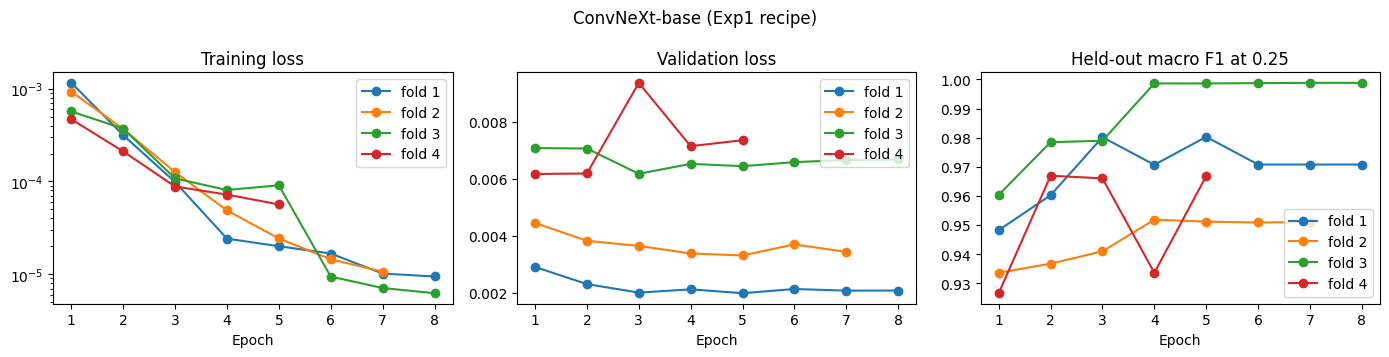

In [6]:
import matplotlib.pyplot as plt

histories = {fold: epoch_history(fold_dir(MODEL_DIR, fold)) for fold in range(5) if (fold_dir(MODEL_DIR, fold) / 'curves').is_dir()}
histories = {fold: rows for fold, rows in histories.items() if rows}
if histories:
    figure, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for fold, rows in histories.items():
        for axis, name in zip(axes, ('train_loss', 'val_loss', 'val_macro_f1')):
            points = [(row['epoch'], row[name]) for row in rows if name in row]
            if points:
                axis.plot(*zip(*points), marker='o', label=f'fold {fold}')
        best = max((row for row in rows if 'val_macro_f1' in row), key=lambda row: row['val_macro_f1'])
        print(f"fold {fold}: {len(rows)} epochs, best held-out macro F1 {best['val_macro_f1']:.5f} at epoch {best['epoch']}")
    for axis, title in zip(axes, ('Training loss', 'Validation loss', 'Held-out macro F1 at 0.25')):
        axis.set(title=title, xlabel='Epoch')
        axis.legend()
    axes[0].set_yscale('log')
    figure.suptitle(RECIPE.title)
    figure.tight_layout()
    figure.savefig(MODEL_DIR / 'curves.png', dpi=140)
    plt.show()
else:
    print('No trained fold has curves yet.')

## Cross-validation score at the fixed threshold 0.25

This needs all five folds. For each fold we report the held-out macro F1 at 0.25 and per-label F1 and AP. Below the table come the mean and standard deviation over the folds, and the pooled OOF score, which is macro F1 over all 12,260 images at once. The pooled score is the one to compare between models. The fold scores show how much one fold can move. The fold-0 row is the earlier Exp1 run's score (0.97518), so the table also shows whether fold 0 was typical.

The OOF scores are still a little optimistic, because each fold's checkpoint was selected on that fold. That bias is the same for every model in this folder, so the comparison between models stays fair.

In [3]:
completed = [fold for fold in range(5) if fold_status(MODEL_DIR, fold) == 'completed']
CV_READY = len(completed) == 5 and not SMOKE_TEST
if not CV_READY:
    print(f'The CV results need all five folds; completed: {completed}.' + (' A smoke run has no results.' if SMOKE_TEST else ''))
else:
    cv = collect_predictions(MODEL_DIR, train_rows, fold_by_id, test_ids)
    print(f"{'fold':<5} {'source':<9} {'macro F1':>9} " + ' '.join(f'{label:>8}' for label in LABEL_COLUMNS) + f" {'macro AP':>9}")
    fold_scores = {}
    for fold in range(5):
        held_out = cv.folds == fold
        scores = score_probabilities(cv.targets[held_out], cv.oof[held_out], RECIPE.threshold)
        fold_scores[fold] = scores
        print(f"{fold:<5} {cv.records[fold]['source']:<9} {scores['macro_f1']:>9.5f} " + ' '.join(f"{scores['per_label_f1'][label]:>8.4f}" for label in LABEL_COLUMNS) + f" {scores['macro_ap']:>9.5f}")
    values = np.array([scores['macro_f1'] for scores in fold_scores.values()])
    pooled = score_probabilities(cv.targets, cv.oof, RECIPE.threshold)
    pooled_05 = score_probabilities(cv.targets, cv.oof, 0.5)
    print(f'\nMean over folds: {values.mean():.5f} +- {values.std(ddof=1):.5f} (min {values.min():.5f}, max {values.max():.5f})')
    print(f"Pooled OOF macro F1 at 0.25: {pooled['macro_f1']:.5f}; at 0.5: {pooled_05['macro_f1']:.5f}; macro AP {pooled['macro_ap']:.5f}")
    decided = cv.oof >= RECIPE.threshold
    print('\nOOF mistakes at 0.25 (missed / false alarms):',
          {label: (int((~decided & (cv.targets == 1))[:, i].sum()), int((decided & (cv.targets == 0))[:, i].sum())) for i, label in enumerate(LABEL_COLUMNS)})

fold  source     macro F1      Cat      Dog    Moris    Motya  Biatrix  macro AP
0     imported    0.97518   0.9966   0.9970   1.0000   0.9412   0.9412   0.99443
1     trained     0.98028   0.9990   0.9985   0.9565   1.0000   0.9474   0.99848
2     trained     0.95189   0.9980   0.9975   0.8889   0.8750   1.0000   0.98701
3     trained     0.99881   0.9975   0.9965   1.0000   1.0000   1.0000   0.99956
4     trained     0.96695   0.9966   0.9970   0.9000   1.0000   0.9412   0.99993

Mean over folds: 0.97462 +- 0.01727 (min 0.95189, max 0.99881)
Pooled OOF macro F1 at 0.25: 0.97416; at 0.5: 0.97684; macro AP 0.99485

OOF mistakes at 0.25 (missed / false alarms): {'Cat': (11, 14), 'Dog': (10, 17), 'Moris': (2, 4), 'Motya': (2, 1), 'Biatrix': (0, 3)}


## One threshold per label

On the OOF predictions every label gets its own threshold: the middle of the range of thresholds that reach that label's best F1, on a grid from 0.02 to 0.98 in steps of 0.01. The middle of the range is less sensitive to a single photo than either end.

If we choose a threshold on the same predictions we score, the score is optimistic. We therefore also report a **fair** score: for every fold, the thresholds are chosen on the other four folds only and then applied to that fold, and the five held-out folds are scored together. The table lists the five threshold sets as well, so we can see how stable the choice is. The test set uses the thresholds chosen on all five folds.

Read the result with the noise level in mind. With 41–56 photos per named pet, one photo moves that label's F1 by about 0.01 and macro F1 by about 0.002–0.0025. A fair gain below about 0.005 (two photos) is not a real gain.

In [4]:
if CV_READY:
    tuning = nested_thresholds(cv.targets, cv.oof, cv.folds)
    thresholds = np.array([tuning['thresholds'][label] for label in LABEL_COLUMNS])
    fixed = per_label_f1(cv.targets, cv.oof, RECIPE.threshold)
    print(f"{'label':<9}{'photos':>7}{'F1 @0.25':>10}{'threshold':>11}  {'chosen on 4 folds (held-out fold 0..4)':<42}{'F1 tuned':>9}{'F1 fair':>9}")
    for index, label in enumerate(LABEL_COLUMNS):
        by_fold = ' '.join(f"{tuning['thresholds_by_held_out_fold'][fold][label]:.2f}" for fold in range(5))
        print(f"{label:<9}{int(cv.targets[:, index].sum()):>7}{fixed[index]:>10.4f}{thresholds[index]:>11.2f}  {by_fold:<42}"
              f"{tuning['optimistic_per_label_f1'][label]:>9.4f}{tuning['fair_per_label_f1'][label]:>9.4f}")
    print(f"{'macro':<9}{'':>7}{fixed.mean():>10.5f}{'':>11}  {'':<42}{tuning['optimistic_macro_f1']:>9.5f}{tuning['fair_macro_f1']:>9.5f}")
    print(f"\nFair gain of per-label thresholds over 0.25: {tuning['fair_macro_f1'] - fixed.mean():+.5f} macro F1")

label     photos  F1 @0.25  threshold  chosen on 4 folds (held-out fold 0..4)     F1 tuned  F1 fair
Cat         5077    0.9975       0.29  0.29 0.51 0.26 0.43 0.44                     0.9975   0.9973
Dog         5025    0.9973       0.65  0.65 0.65 0.60 0.30 0.33                     0.9974   0.9971
Moris         56    0.9474       0.34  0.34 0.55 0.08 0.34 0.34                     0.9643   0.9381
Motya         42    0.9639       0.11  0.11 0.11 0.27 0.11 0.11                     0.9647   0.9639
Biatrix       41    0.9647       0.51  0.51 0.75 0.51 0.51 0.51                     0.9880   0.9630
macro              0.97416                                                         0.98238  0.97187

Fair gain of per-label thresholds over 0.25: -0.00229 macro F1


## The fold ensemble on the test set

The test prediction of this model is the equal-weight mean of the five fold models' probabilities. We compare it with the single fold-0 model that was submitted before (Exp1, public 0.97003). The counts show how many test photos each version calls a named pet, and how many test cells the fold models disagree on. A cell is one image-label pair. A cell on which the fold models disagree is decided by the average. The test labels are hidden, so this shows how much the fold ensemble changes, not whether the changes are right.

One caveat for the tuned thresholds: an average of five models is a little less extreme than one model, so a threshold tuned on single-model OOF probabilities may fit the fold mean slightly differently. The leaderboard shows whether that matters.

In [5]:
if CV_READY:
    test_mean = cv.test_mean
    single = cv.test_by_fold[0]
    named = [LABEL_COLUMNS.index(label) for label in ('Moris', 'Motya', 'Biatrix')]
    print(f"{'test positives':<34}" + ''.join(f'{label:>9}' for label in LABEL_COLUMNS))
    for title, decided in (
        ('fold-0 model alone, 0.25', single >= RECIPE.threshold),
        *((f'fold-{fold} model alone, 0.25', cv.test_by_fold[fold] >= RECIPE.threshold) for fold in range(1, 5)),
        ('fold ensemble, 0.25', test_mean >= RECIPE.threshold),
        ('fold ensemble, per-label thresholds', test_mean >= thresholds),
    ):
        print(f'{title:<34}' + ''.join(f'{int(decided[:, index].sum()):>9}' for index in range(len(LABEL_COLUMNS))))
    votes = np.stack([cv.test_by_fold[fold] >= RECIPE.threshold for fold in range(5)]).sum(axis=0)
    split = (votes > 0) & (votes < 5)
    print(f'\nCells where the five fold models disagree at 0.25: {int(split.sum())} ({int(split[:, named].sum())} named-pet cells)')
    changed = (test_mean >= RECIPE.threshold) != (single >= RECIPE.threshold)
    print(f'Fold ensemble vs the fold-0 model alone, both at 0.25: {int(changed.sum())} cells change ({int(changed[:, named].sum())} named-pet)')
    changed = (test_mean >= thresholds) != (test_mean >= RECIPE.threshold)
    print(f'Per-label thresholds vs 0.25 on the fold ensemble: {int(changed.sum())} cells change ({int(changed[:, named].sum())} named-pet)')

test positives                          Cat      Dog    Moris    Motya  Biatrix
fold-0 model alone, 0.25               7781     7675      162      129      187
fold-1 model alone, 0.25               7762     7678      169      131      176
fold-2 model alone, 0.25               7771     7675      181      133      188
fold-3 model alone, 0.25               7766     7672      176      120      178
fold-4 model alone, 0.25               7783     7665      174      142      191
fold ensemble, 0.25                    7776     7674      178      133      184
fold ensemble, per-label thresholds     7773     7655      168      144      178

Cells where the five fold models disagree at 0.25: 181 (90 named-pet cells)
Fold ensemble vs the fold-0 model alone, both at 0.25: 71 cells change (39 named-pet)
Per-label thresholds vs 0.25 on the fold ensemble: 49 cells change (27 named-pet)


## Save the CV result and the submission files

`cv.json` in the model folder holds the CV scores, the thresholds and the hashes of the five fold records it was built from. `oof.csv` (12,260 rows with their fold) and `test_mean.csv` (the fold ensemble) are the inputs of `06_cv_ensemble.ipynb`. Two CSVs go to `submissions/`: `cv_convnext_5fold_025.csv` (threshold 0.25) and `cv_convnext_5fold_perlabel.csv` (per-label thresholds). Submitting both separates the effect of the fold ensemble from the effect of the thresholds. Nothing is overwritten. Upload by hand and add the public scores to `public_leaderboard_score` in `cv.json` and to the table below.

In [6]:
if CV_READY:
    summary = {
        'cv': {
            'threshold': RECIPE.threshold,
            'per_fold_macro_f1': {str(fold): scores['macro_f1'] for fold, scores in fold_scores.items()},
            'per_fold_per_label_f1': {str(fold): scores['per_label_f1'] for fold, scores in fold_scores.items()},
            'mean_fold_macro_f1': float(values.mean()), 'std_fold_macro_f1': float(values.std(ddof=1)),
            'pooled_oof': pooled, 'pooled_oof_macro_f1_at_0_5': pooled_05['macro_f1'],
        },
        'per_label_thresholds': tuning,
        'test': {'method': 'equal-weight mean of the five fold models',
                 'positives_at_0_25': dict(zip(LABEL_COLUMNS, map(int, (test_mean >= RECIPE.threshold).sum(axis=0)))),
                 'positives_per_label_thresholds': dict(zip(LABEL_COLUMNS, map(int, (test_mean >= thresholds).sum(axis=0))))},
    }
    record = save_cv_summary(MODEL_DIR, ROOT, cv, RECIPE, summary)
    print('CV record:', MODEL_DIR / 'cv.json')
    if BUILD_SUBMISSION:
        sample = DATA_DIR / 'sample_submission.csv'
        for suffix, rows in (('025', form_submission(sample, test_ids, test_mean, RECIPE.threshold)),
                             ('perlabel', form_submission_per_label(sample, test_ids, test_mean, thresholds))):
            path = ROOT / 'submissions' / f'cv_{RECIPE.key}_5fold_{suffix}.csv'
            if path.exists():
                print('Kept existing', path.relative_to(ROOT))
            else:
                write_submission(path, rows)
                print('Wrote', path.relative_to(ROOT), {label: sum(row[label] for row in rows) for label in LABEL_COLUMNS})
else:
    print('Nothing saved yet; the CV summary needs all five folds.')

CV record: /Users/allakovalcuk/AI301/deep-learning-assignment2/experiments/cv/convnext/cv.json
Wrote submissions/cv_convnext_5fold_025.csv {'Cat': 7776, 'Dog': 7674, 'Moris': 178, 'Motya': 133, 'Biatrix': 184}
Wrote submissions/cv_convnext_5fold_perlabel.csv {'Cat': 7773, 'Dog': 7655, 'Moris': 168, 'Motya': 144, 'Biatrix': 178}


## Results and conclusions

_Fill in after all five folds and the two uploads. The numbers come from the cells above, the public scores from Kaggle._

| Version | CV macro F1 | Public LB |
|---|---:|---:|
| Exp1 fold-0 run, threshold 0.25 (before) | 0.97518 (fold 0 only) | 0.97003 |
| Five folds: mean ± std of the fold scores, 0.25 | | — |
| Five folds: pooled OOF, 0.25 (`cv_convnext_5fold_025.csv`) | | |
| Five folds: per-label thresholds, fair (`cv_convnext_5fold_perlabel.csv`) | | |

Questions to answer here:

1. **Was fold 0 typical for this model?** Compare its row with the other four and with the mean.
2. **Does the fold ensemble beat the single fold-0 model on the leaderboard,** at the same threshold 0.25?
3. **Do per-label thresholds help?** Compare the fair OOF gain with the leaderboard difference between the two CSVs, and say which labels moved.
4. **How far is CV from the leaderboard now?** The fold-0 gaps were 0.005–0.058.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/AI301-stage2/cv
!zip -r ../cv_convnext_results.zip convnext -x "*.ckpt" "*/wandb/*" "*.partial"
!ls -lh ../cv_convnext_results.zip


Mounted at /content/drive
/content/drive/MyDrive/AI301-stage2/cv
	zip warning: name not matched: convnext/fold2/wandb/run-20261110_160007-convnext-fold2-1794322588/logs/debug-core.log
	zip warning: name not matched: convnext/fold2/wandb/latest-run/logs/debug-core.log
	zip warning: name not matched: convnext/fold3/wandb/run-20261110_162813-convnext-fold3-1794328092/logs/debug-core.log
	zip warning: name not matched: convnext/fold3/wandb/latest-run/logs/debug-core.log
Scanning files 
	zip warning: name not matched: convnext/fold4/wandb/run-20261110_165940-convnext-fold4-1794329979/logs/debug-core.log
	zip warning: name not matched: convnext/fold4/wandb/latest-run/logs/debug-core.log
  adding: convnext/ (stored 0%)
  adding: convnext/fold0/ (stored 0%)
  adding: convnext/fold0/oof.csv (deflated 51%)
  adding: convnext/fold0/fold.json (deflated 59%)
  adding: convnext/fold0/test.csv (deflated 51%)
  adding: convnext/fold1/ (stored 0%)
  adding: convnext/fold1/wandb_id.txt (stored 0%)
  add